# OPTIMIZACIÓN DE HIPERPARÁMETROS PARA RANDOM FOREST

**Por**: Daniela Andrea Torres Gómez


**PARTE 3:** 

2. Explore la regresión usando RandomForest con los datos de California Housing (sklearn.datasets.fetch_california_housing). Este dataset busca estimar el valor de una vivienda a partir de 8 características. Optimice los hiperparámetros empleando los métodos de búsqueda de grilla, búsqueda aleatoria y optimización bayesiana y compare las diferentes métricas de desempeño.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
from sklearn import datasets

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# Metricas de desempeño
from sklearn import metrics

#Importamos el modelo de bosques aleatorios para su entrenamiento
from sklearn.model_selection import GridSearchCV

## Regresión

**housing**

In [7]:
from sklearn.ensemble import RandomForestRegressor
from skopt import BayesSearchCV
from sklearn.model_selection import RandomizedSearchCV

In [8]:
dataset_house = datasets.fetch_california_housing(as_frame=True)

In [9]:
print(dataset_house.feature_names)
print(dataset_house.target_names)

['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
['MedHouseVal']


In [10]:
df2 = pd.DataFrame(dataset_house.data)
df2.columns = dataset_house.feature_names
df2['target'] = dataset_house.target
df2.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [11]:
df2.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [12]:
#Vamos a dividir los datos entre las muestras de entrenamiento y prueba

#Muestras
X2 = df2.drop('target', axis=1)

#Etiquetas
y2 = df2['target']

#Seleccionamos 70% de muestras para entrenamiento y 30% para prueba
X_train_house, X_test_house, y_train_house, y_test_house = train_test_split(X2, y2, test_size=0.3, random_state=42)

# normalizar los datos
scaler = MinMaxScaler()
X_train_house = scaler.fit_transform(X_train_house)
X_test_house = scaler.transform(X_test_house)
print("Tamaño de los datos de entrenamiento:", X_train_house.shape, "Tamaño de los datos de prueba:", X_test_house.shape)

Tamaño de los datos de entrenamiento: (14448, 8) Tamaño de los datos de prueba: (6192, 8)


### Entrenamiento del modelo: Método de grilla

In [9]:
#Creamos la grilla con los parametros a seleccionar
param_grid = {
    'n_estimators': np.arange(10,100,10),
    'criterion': ['squared_error', 'absolute_error'],
    'max_depth': [1, 5, 10]
}

#Defimos el modelo base
base_estimator_4 = RandomForestRegressor(n_estimators=90, random_state=0)

#Realizamos la busqueda de los hiperparametros
RF_gridSearch_4 = GridSearchCV(base_estimator_4, param_grid)

# Entrenamos el modelo con la mejor combinacion de hiperparametros
RF_gridSearch_4.fit(X_train_house,y_train_house)

#Podemos ver que parametros fueron los seleccionados
RF_gridSearch_4.best_params_

{'criterion': 'squared_error', 'max_depth': 10, 'n_estimators': np.int64(80)}

In [13]:
#Evaluamos el desempeño
y_pred_house_4 = RF_gridSearch_4.best_estimator_.predict(X_test_house)

print("MAE: ", metrics.mean_absolute_error(y_test_house,y_pred_house_4))
print("MSE: ", metrics.mean_squared_error(y_test_house,y_pred_house_4))
print("R2:  ", metrics.r2_score(y_test_house,y_pred_house_4))

MAE:  0.3659473456798806
MSE:  0.29165367491861927
R2:   0.7777944664834731


### Entrenamiento del modelo: Método de búsqueda aleatoria

In [ ]:
#Creamos la grilla de hiperparametros, entre las cuales se seleccionara de forma
#aleatoria la mejor configuracion
param_grid_5 = {'n_estimators': np.arange(10,210,10),
              'criterion': ['squared_error','absolute_error'],
              'max_depth': [3,5,10]
}
#Defimos el modelo base
base_estimator_5 = RandomForestRegressor(random_state=0)

#Realizamos la busqueda de los hiperparametros
RF_randomSearch_5 = RandomizedSearchCV(base_estimator_5,param_grid_5,n_iter=12)

# fit con la mejor combinacion de hiperparametros
RF_randomSearch_5.fit(X_train_house,y_train_house)

#Podemos ver que parametros fueron los seleccionados
RF_randomSearch_5.best_params_

{'n_estimators': np.int64(130), 'max_depth': 10, 'criterion': 'squared_error'}

In [17]:
#Evaluamos el desempeño
y_pred_house_5 = RF_randomSearch_5.best_estimator_.predict(X_test_house)

print("MAE: ", metrics.mean_absolute_error(y_test_house,y_pred_house_5))
print("MSE: ", metrics.mean_squared_error(y_test_house,y_pred_house_5))
print("R2:  ", metrics.r2_score(y_test_house,y_pred_house_5))

MAE:  0.4904942980536807
MSE:  0.4536271007451937
R2:   0.6543899130817842


### Entrenamiento del modelo: Método Bayesiano

In [ ]:
param_grid_6 = {'n_estimators': np.arange(10,210,10),
              'criterion': ['squared_error','absolute_error'],
              'max_depth': [2,3,5,10]
}
#Defimos el modelo base
base_estimator_6 = RandomForestRegressor(random_state=0)

#Realizamos la busqueda de los hiperparametros
RF_optBay_6 = BayesSearchCV(base_estimator_6,param_grid_6,n_iter=12)

# fit con la mejor combinacion de hiperparametros
RF_optBay_6.fit(X_train_house,y_train_house)

#Podemos ver que parametros fueron los seleccionados
RF_optBay_6.best_params_

OrderedDict([('criterion', 'squared_error'),
             ('max_depth', 10),
             ('n_estimators', 200)])

In [15]:
#Evaluamos el desempeño
y_pred_house_6 = RF_optBay_6.best_estimator_.predict(X_test_house)

print("MAE: ", metrics.mean_absolute_error(y_test_house,y_pred_house_6))
print("MSE: ", metrics.mean_squared_error(y_test_house,y_pred_house_6))
print("R2:  ", metrics.r2_score(y_test_house,y_pred_house_6))

MAE:  0.3666128104062122
MSE:  0.29177597327466626
R2:   0.7777012896309572


**Con el mejor estimador, ver la importancia de las características**

<Axes: >

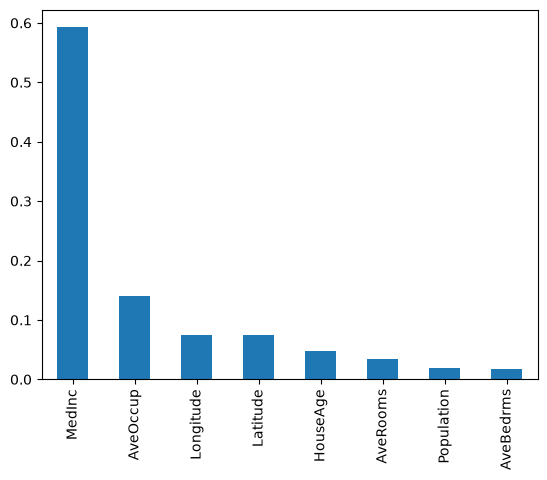

In [ ]:
# Serie con las caracteristicas mas importantes del modelo entrenado, junto con sus nombres
importances = pd.Series(RF_optBay_6.best_estimator_.feature_importances_, index=df2.columns[:-1])
importances.sort_values(ascending=False).plot.bar()

**Predicciones con una característica**

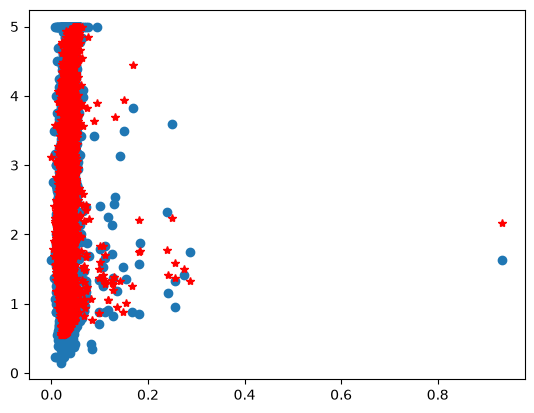

In [17]:
plt.plot(X_test_house.T[2], y_test_house,'o')
plt.plot(X_test_house.T[2], y_pred_house_6,'*r')

### Predicción para un dato:

In [40]:
indice = 5
dato = pd.DataFrame(X_test_house[indice].reshape(1, -1), columns=df2.columns[:-1])
dato.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,0.290672,0.215686,0.030936,0.025363,0.067182,0.001734,0.162766,0.671315


In [41]:
prediccion = RF_optBay_6.best_estimator_.predict(X_test_house[indice].reshape(1, -1))
print("Predicción para la muestra 1: ", prediccion[0], "Vs. Valor real: ", y_test_house.iloc[indice])

Predicción para la muestra 1:  1.7678114874694077 Vs. Valor real:  1.587
